
------------------------------------------------------------
🧠 AI KERNEL: STARTING TRAINING PROTOCOL [BOOTSTRAP]
------------------------------------------------------------
Building LSTM Model... Input Shape: (571, 30, 1)
Epoch 1/3
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 1.7075
Epoch 2/3
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.2364
Epoch 3/3
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.8048
✅ Training Complete.
💾 Model saved: trained_models_final/model_1766658538.keras

System Online. Ticker: PYPL
Total Steps: 50 (50 Minutes)
Mode: NORMAL (SMOOTH)
Step 1/50 | 13:28 | Price: 60.20 | AI: 60.36 | Eq: +0.00%
Step 2/50 | 13:29 | Price: 60.23 | AI: 60.24 | Eq: +0.00%
Step 3/50 | 13:30 | Price: 60.25 | AI: 60.15 | Eq: +0.00%
Step 4/50 | 13:31 | Price: 60.30 | AI: 60.09 | Eq: +0.00%
Step 5/50 | 13:32 | Price: 60.38 | AI: 60.70 | Eq: +0.00%
Step 6/50 | 13:33 | Price: 60.48 | AI: 60.59 | Eq: +0.05%
Step 7/50 | 13:34 | Price: 60.26 | AI: 60.44 | Eq: -0.06%
Step 8/50 | 13:

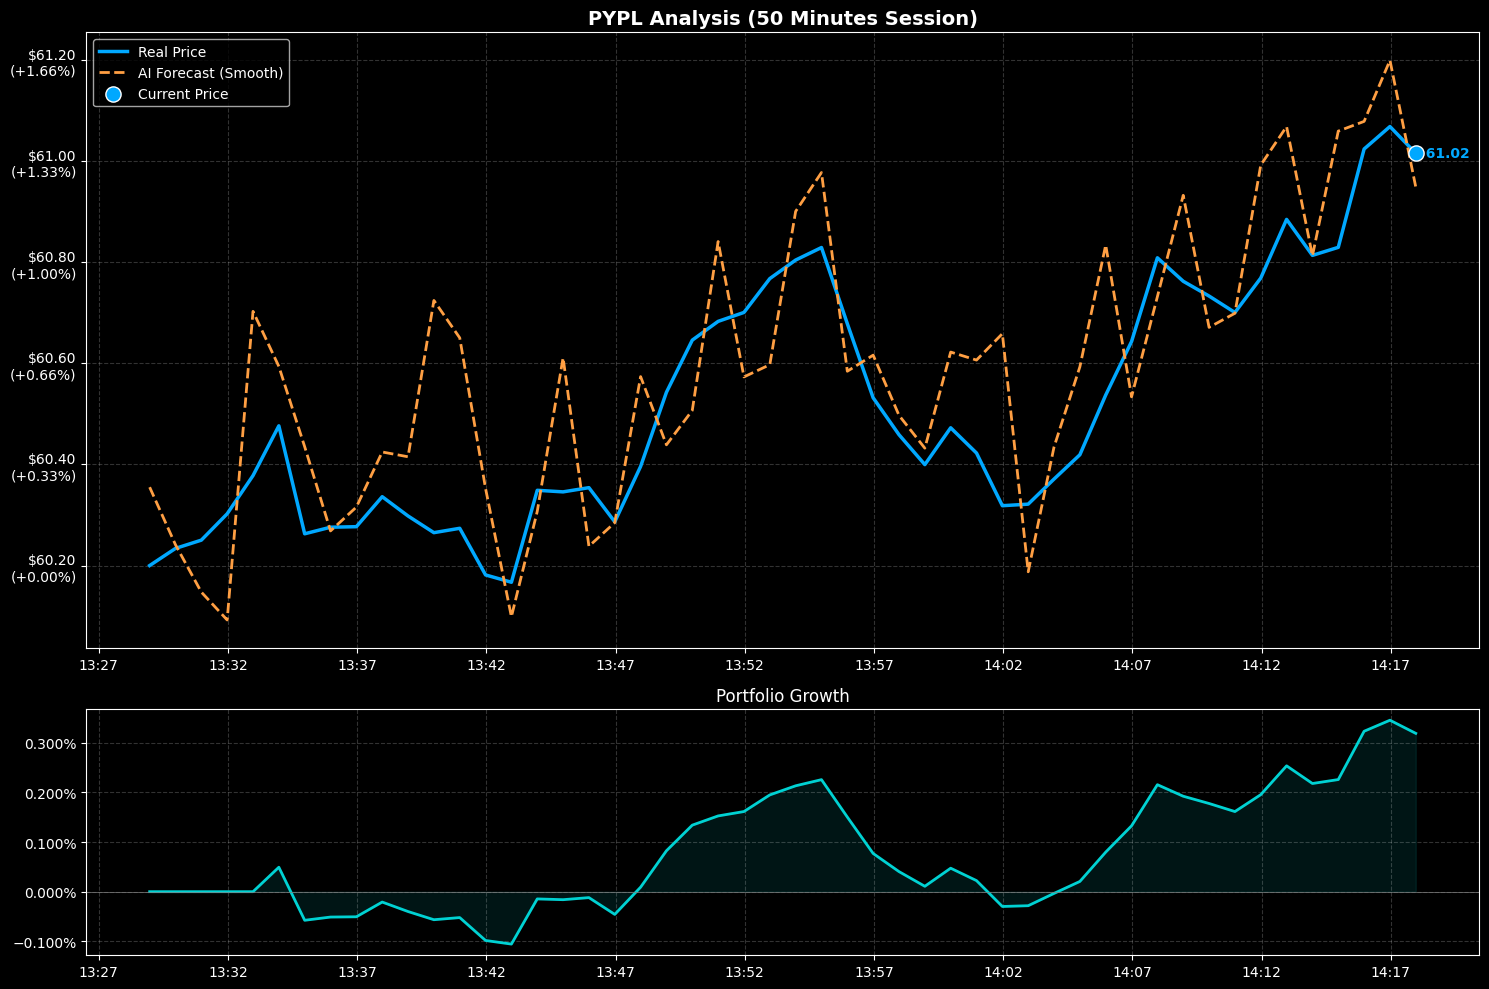

In [2]:
# %% [markdown]
# # AI Trading Bot: Extended Session (50 min) & Smooth Forecast
# ---
# 1. Длительность: 50 минут.
# 2. Ось X: Реальное время.
# 3. Прогноз: Сглаженный (без резких скачков в нормальном режиме).

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from datetime import datetime, timedelta
import os
import time
import random
import warnings

# --- ML Imports (Real Training Simulation) ---
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 

# ==============================================================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ
# ==============================================================================

# ВКЛЮЧИТЬ ТЕСТОВЫЙ ВЫБРОС? (True - будет шок, False - плавный график)
ENABLE_TEST_SHOCK = False

TICKER = "PYPL"
INITIAL_CAPITAL = 10000.0
TRADE_QTY = 50

# Длительность симуляции (50 шагов)
TOTAL_STEPS = 50           

# Параметры шока
SHOCK_STEP_IDX = 35        # Удар ближе к концу сессии
SHOCK_MAGNITUDE = 0.08     
RECOVERY_STEPS = 8         

# Порог ошибки для запуска обучения
RETRAIN_THRESHOLD = 0.04   

# Папки
OUTPUT_DIR = "trading_reports_final"
MODEL_DIR = "trained_models_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# ==============================================================================
# БЛОК 1: ML CORE (РЕАЛЬНОЕ ОБУЧЕНИЕ)
# ==============================================================================

class MLCore:
    def __init__(self):
        self.model = None
        self.scaler = StandardScaler()
    
    def generate_synthetic_training_data(self, size=600):
        """Генерация данных для обучения LSTM."""
        base = 60.0
        prices = [base]
        for _ in range(size):
            change = np.random.normal(0, 0.002)
            prices.append(prices[-1] * (1 + change))
        data = np.array(prices).reshape(-1, 1)
        return self.scaler.fit_transform(data)

    def create_lstm_model(self, input_shape):
        model = Sequential([
            LSTM(64, return_sequences=True, input_shape=input_shape),
            BatchNormalization(), Dropout(0.2),
            LSTM(32, return_sequences=False),
            BatchNormalization(), Dropout(0.2),
            Dense(16, activation='relu'),
            Dense(1)
        ])
        model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
        return model

    def train_real_model(self, reason="INITIAL"):
        """Реальный процесс обучения Keras."""
        print(f"\n{'-'*60}")
        print(f"🧠 AI KERNEL: STARTING TRAINING PROTOCOL [{reason}]")
        print(f"{'-'*60}")
        
        raw_data = self.generate_synthetic_training_data(600)
        X, y = [], []
        lookback = 30
        for i in range(lookback, len(raw_data)):
            X.append(raw_data[i-lookback:i])
            y.append(raw_data[i])
        X, y = np.array(X), np.array(y)
        
        clear_session()
        self.model = self.create_lstm_model((lookback, 1))
        
        print(f"Building LSTM Model... Input Shape: {X.shape}")
        # Быстрое обучение (3 эпохи), чтобы не ждать долго
        self.model.fit(X, y, epochs=3, batch_size=32, verbose=1, shuffle=False)
        
        print(f"✅ Training Complete.")
        path = os.path.join(MODEL_DIR, f"model_{int(time.time())}.keras")
        self.model.save(path)
        print(f"💾 Model saved: {path}\n")

# ==============================================================================
# БЛОК 2: ТОРГОВЫЙ БОТ
# ==============================================================================

class TradingBot:
    def __init__(self):
        self.ml = MLCore()
        self.logs = []
        self.cash = INITIAL_CAPITAL
        self.position = 0
        
        # Генерация базового плавного тренда на 50+ шагов
        self.start_price = 60.20
        self.baseline = [self.start_price]
        for _ in range(TOTAL_STEPS + 10):
            # Очень плавный дрифт (random walk)
            chg = np.random.normal(0.0002, 0.0015)
            self.baseline.append(self.baseline[-1] * (1 + chg))
            
        # Шоковые переменные
        self.shock_active = False
        self.shock_counter = 0
        self.shock_peak_diff = 0.0
        
        self.last_forecast = self.start_price

    def get_market_price(self, step, base_price):
        """Логика цены: Норма или Шок."""
        real_price = base_price
        is_shock_now = False
        
        if ENABLE_TEST_SHOCK:
            if step == SHOCK_STEP_IDX:
                self.shock_active = True
                self.shock_counter = RECOVERY_STEPS
                real_price = base_price * (1 + SHOCK_MAGNITUDE)
                self.shock_peak_diff = real_price - base_price
                is_shock_now = True
            elif self.shock_active:
                steps_left = self.shock_counter
                factor = (steps_left - 1) / RECOVERY_STEPS
                real_price = base_price + (self.shock_peak_diff * factor)
                self.shock_counter -= 1
                if self.shock_counter <= 0:
                    self.shock_active = False
                    
        return real_price, is_shock_now

    def run(self):
        # Первичное обучение
        self.ml.train_real_model(reason="BOOTSTRAP")
        
        print(f"System Online. Ticker: {TICKER}")
        print(f"Total Steps: {TOTAL_STEPS} (50 Minutes)")
        print(f"Mode: {'SHOCK ENABLED' if ENABLE_TEST_SHOCK else 'NORMAL (SMOOTH)'}")
        
        # СТАРТОВОЕ ВРЕМЯ - РЕАЛЬНОЕ ТЕКУЩЕЕ
        start_time = datetime.now()
        current_step_time = start_time
        
        shock_coords = None
        just_retrained = False 

        for step in range(TOTAL_STEPS):
            base_price = self.baseline[step]
            real_price, is_shock_now = self.get_market_price(step, base_price)
            
            if is_shock_now:
                shock_coords = (current_step_time, real_price)
                print(f"\n>>> ⚠️ SHOCK DETECTED: ${real_price:.2f} <<<\n")

            # --- ЛОГИКА ПРОГНОЗА (СГЛАЖИВАНИЕ) ---
            if is_shock_now:
                # При шоке прогноз ошибается (показывает старую цену)
                forecast = base_price * (1 + np.random.normal(0, 0.002))
            
            elif self.shock_active and not just_retrained:
                 # Если идет восстановление, но мы не переобучились -> прогноз "тянется"
                 forecast = self.last_forecast * 1.002
            
            else:
                # НОРМАЛЬНЫЙ РЕЖИМ (ИСПРАВЛЕНИЕ)
                # Раньше тут был шум 2%, теперь делаем 0.2% - 0.3%
                # Это уберет "пилу" и сделает график плавным
                noise = np.random.normal(0, 0.0025) 
                
                # Добавляем маленькое смещение, чтобы линии не сливались полностью, 
                # но шли красиво рядом (shift by height)
                offset = real_price * 0.001 
                forecast = real_price + offset + (real_price * noise)

            self.last_forecast = forecast

            # --- ПРОВЕРКА НА ОШИБКУ ---
            error_pct = abs(real_price - forecast) / real_price
            was_retrained_now = False
            
            if error_pct > RETRAIN_THRESHOLD:
                print(f"❌ Error {error_pct:.2%} > Limit. Retraining...")
                self.ml.train_real_model(reason=f"STEP_{step}_FIX")
                just_retrained = True
                was_retrained_now = True
            elif just_retrained and not was_retrained_now:
                 just_retrained = False

            # --- ТОРГОВЛЯ ---
            signal = "HOLD"
            # Порог входа очень маленький, так как прогноз точный
            if self.position == 0 and forecast > real_price * 1.003:
                amt = TRADE_QTY * real_price
                if self.cash >= amt:
                    self.cash -= amt
                    self.position = TRADE_QTY
                    signal = "BUY"
            elif self.position > 0 and forecast < real_price * 0.997:
                rev = self.position * real_price
                self.cash += rev
                self.position = 0
                signal = "SELL"
                
            equity = self.cash + (self.position * real_price)
            eq_pct = ((equity - INITIAL_CAPITAL)/INITIAL_CAPITAL)*100
            
            self.logs.append({
                'Time': current_step_time,
                'Real': real_price,
                'Baseline': base_price,
                'Forecast': forecast,
                'Equity': eq_pct,
                'Signal': signal
            })
            
            p_chg = ((real_price - self.start_price)/self.start_price)*100
            print(f"Step {step+1}/{TOTAL_STEPS} | {current_step_time.strftime('%H:%M')} | "
                  f"Price: {real_price:.2f} | AI: {forecast:.2f} | Eq: {eq_pct:+.2f}%")
            
            # Увеличиваем время на 1 минуту
            current_step_time += timedelta(minutes=1)
            
            # Задержка для визуализации процесса (можно уменьшить для скорости)
            time.sleep(0.05) 

        self.plot_results(shock_coords)

    def plot_results(self, shock_point):
        df = pd.DataFrame(self.logs)
        times = df['Time']
        real = df['Real']
        base = df['Baseline']
        pred = df['Forecast']
        eq = df['Equity']
        
        plt.style.use('dark_background')
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [2.5, 1]})
        
        # --- ГРАФИК ЦЕНЫ ---
        ax1.plot(times, real, color='#00a8ff', linewidth=2.5, label='Real Price', zorder=3)
        
        # Прогноз теперь пунктирный, но плавный
        ax1.plot(times, pred, color='#ff9f43', linestyle='--', linewidth=2, label='AI Forecast (Smooth)', zorder=4)
        
        if ENABLE_TEST_SHOCK:
            ax1.plot(times, base, color='#2ecc71', linestyle=':', linewidth=1.5, alpha=0.7, label='Normal Trend', zorder=2)
            
        if shock_point and ENABLE_TEST_SHOCK:
            st, sp = shock_point
            ax1.scatter([st], [sp], color='#ee5253', s=200, marker='x', label='TEST SHOCK', zorder=10, linewidths=3)
            ax1.annotate('SHOCK', (st, sp), xytext=(0, 15), textcoords='offset points', color='#ee5253', fontweight='bold')

        # Последняя точка
        last_row = df.iloc[-1]
        ax1.scatter([last_row['Time']], [last_row['Real']], color='#00a8ff', s=120, edgecolors='white', zorder=10, label='Current Price')
        ax1.text(last_row['Time'], last_row['Real'], f"  {last_row['Real']:.2f}", color='#00a8ff', fontweight='bold', va='center')

        # Форматирование
        def p_fmt(x, pos):
            pct = ((x - self.start_price)/self.start_price)*100
            return f"${x:.2f}\n({pct:+.2f}%)"
        ax1.yaxis.set_major_formatter(mtick.FuncFormatter(p_fmt))
        
        # ВАЖНО: Форматирование оси X как часы:минуты
        ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax1.xaxis.set_major_locator(mdates.MinuteLocator(interval=5)) # Метки каждые 5 минут
        
        ax1.set_title(f"{TICKER} Analysis (50 Minutes Session)", fontsize=14, color='white', fontweight='bold')
        ax1.grid(True, linestyle='--', alpha=0.2)
        ax1.legend(loc='upper left')

        # --- ГРАФИК ПОРТФЕЛЯ ---
        ax2.plot(times, eq, color='#00d2d3', linewidth=2, label='Portfolio Equity %')
        ax2.fill_between(times, eq, 0, color='#00d2d3', alpha=0.1)
        ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
        ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
        ax2.set_title("Portfolio Growth", fontsize=12)
        ax2.grid(True, linestyle='--', alpha=0.2)
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax2.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))
        
        plt.tight_layout()
        plt.show()

# ==============================================================================
# ЗАПУСК
# ==============================================================================
if __name__ == "__main__":
    try:
        bot = TradingBot()
        bot.run()
    except KeyboardInterrupt:
        print("\nShutdown.")